# 5. Explicabilidad del modelo con SHAP (RNF4, RF4)
**RetailNova — Caso 1 (SCY1102 Gestión de Proyectos de Datos, Sección 001D)** · Hurtubia · Pacheco · Curi · Gómez

SHAP explica qué variables empujan la probabilidad de abandono, a nivel global y para un cliente individual (lo que pide RF4: una explicación por clasificación para el equipo comercial). Código en `src/explicabilidad.py`.

## 5.1 Configuración

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar src/ desde notebooks/

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as cfg

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

In [2]:
from src.modelado import cargar_modelo, dividir_datos
from src.explicabilidad import calcular_shap
df = pd.read_csv(cfg.CSV_PREPARADO)
pipe = cargar_modelo()
_, X_test, *_ = dividir_datos(df)
shap_df, idx = calcular_shap(pipe, X_test, muestra=2000)
print("Clientes explicados:", len(shap_df))

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


Clientes explicados: 2000


## 5.2 Importancia global
Impacto medio absoluto (|SHAP|) de cada variable sobre la predicción.

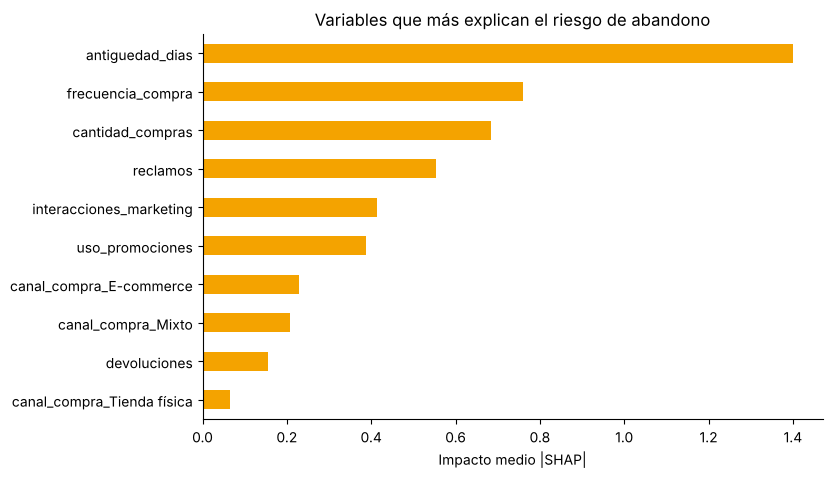

antiguedad_dias              1.400
frecuencia_compra            0.759
cantidad_compras             0.683
reclamos                     0.553
interacciones_marketing      0.415
uso_promociones              0.387
canal_compra_E-commerce      0.228
canal_compra_Mixto           0.208
devoluciones                 0.155
canal_compra_Tienda física   0.066
dtype: float64

In [3]:
imp = shap_df.abs().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
imp.head(10).sort_values().plot(kind="barh", color="#F4A300", ax=ax)
ax.set_xlabel("Impacto medio |SHAP|"); ax.set_title("Variables que más explican el riesgo de abandono")
plt.show()
imp.head(10).round(3)

**Lectura:** la antigüedad, la frecuencia y la cantidad de compras y los reclamos concentran la explicación. Son variables accionables para el equipo comercial (a diferencia de la recencia, que se excluyó por fuga de datos).

## 5.3 Ficha explicativa de un cliente

In [4]:
i = 0
fila = shap_df.iloc[i]
cliente = df.loc[idx[i]]
proba = pipe.predict_proba(X_test.loc[[idx[i]]])[0, 1]
print(f"Cliente {cliente['id_cliente']} · probabilidad de abandono: {proba:.1%}\n")
top = fila.abs().sort_values(ascending=False).head(3)
for v in top.index:
    print(f"- {v}: {'aumenta' if fila[v] > 0 else 'reduce'} el riesgo (impacto {abs(fila[v]):.2f})")

Cliente CL070611 · probabilidad de abandono: 95.7%

- reclamos: aumenta el riesgo (impacto 2.29)
- antiguedad_dias: aumenta el riesgo (impacto 1.07)
- frecuencia_compra: aumenta el riesgo (impacto 0.91)


## 5.4 Guardado
`explicar` guarda el resumen en `output/resultados/explicabilidad/`.

In [5]:
from src.explicabilidad import explicar
_ = explicar(df, pipe, muestra=2000)

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


Top 5 variables que más explican el riesgo:
antiguedad_dias           1.400
frecuencia_compra         0.759
cantidad_compras          0.683
reclamos                  0.553
interacciones_marketing   0.415


**Siguiente:** `06_scoring_y_panel.ipynb`.